In [1]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/home/administrateur/chicago-crime-data-platform/.venv/lib/python3.12/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/home/administrateur/chicago-crime-data-platform/.venv/lib/python3.12/site-packages/traitlets/config/application.py", line 1080, in launch_instance
    app.start()
  File "/home/administrateur/chicago-crime-data-platform/.venv/lib/python3.12/site-p

AttributeError: _ARRAY_API not found

In [2]:
# Pour afficher les graphiques dans le notebook
%matplotlib inline

# Style des graphiques
sns.set_theme(style="whitegrid", palette="viridis")

In [3]:
with open("../data/raw/sample_1000.json") as f:
    data = json.load(f)

df = pd.DataFrame(data)
print(f"Shape : {df.shape}")
print(f"Colonnes : {len(df.columns)}")

Shape : (1000, 22)
Colonnes : 22


In [4]:
df.head(3)

,id,case_number,date,block,iucr,primary_type,description,location_description,arrest,domestic,...,ward,community_area,fbi_code,x_coordinate,y_coordinate,year,updated_on,latitude,longitude,location
0,14379234,JK476337,2026-11-02T00:00:00.000,050XX W SCHUBERT AVE,1152,DECEPTIVE PRACTICE,ILLEGAL USE CASH CARD,OTHER (SPECIFY),False,False,...,31,19,11,1142302,1917487,2026,2026-11-09T15:55:38.000,41.929642701,-87.752499967,"{'latitude': '41.929642701', 'longitude': '-87..."
1,14379045,JK475863,2026-11-02T00:00:00.000,0000X W 111TH PL,0910,MOTOR VEHICLE THEFT,AUTOMOBILE,RESIDENCE,False,False,...,9,49,07,1178013,1831034,2026,2026-11-09T15:55:38.000,41.691669262,-87.623895181,"{'latitude': '41.691669262', 'longitude': '-87..."
2,14377662,JK474304,2026-11-02T00:00:00.000,020XX N MILWAUKEE AVE,0860,THEFT,RETAIL THEFT,SMALL RETAIL STORE,False,False,...,1,22,06,1159682,1913243,2026,2026-11-09T15:55:38.000,41.917656022,-87.688750258,"{'latitude': '41.917656022', 'longitude': '-87..."


In [5]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({
    "missing": missing,
    "pct": missing_pct
}).sort_values("pct", ascending=False)

missing_df[missing_df["missing"] > 0]

,missing,pct
longitude,9,0.9
x_coordinate,9,0.9
location,9,0.9
y_coordinate,9,0.9
latitude,9,0.9
location_description,4,0.4


In [6]:
print(f"Doublons (id) : {df['id'].duplicated().sum()}")
print(f"Doublons (case_number) : {df['case_number'].duplicated().sum()}")

Doublons (id) : 0
Doublons (case_number) : 0


In [7]:
df["primary_type"].value_counts()

primary_type
BATTERY                              260
THEFT                                193
CRIMINAL DAMAGE                      110
MOTOR VEHICLE THEFT                   84
ASSAULT                               70
BURGLARY                              57
OTHER OFFENSE                         47
DECEPTIVE PRACTICE                    35
NARCOTICS                             30
ROBBERY                               24
CRIMINAL TRESPASS                     22
WEAPONS VIOLATION                     19
PUBLIC PEACE VIOLATION                10
CRIMINAL SEXUAL ASSAULT                9
OFFENSE INVOLVING CHILDREN             7
INTERFERENCE WITH PUBLIC OFFICER       4
STALKING                               4
SEX OFFENSE                            4
INTIMIDATION                           2
HOMICIDE                               2
CONCEALED CARRY LICENSE VIOLATION      2
PROSTITUTION                           2
ARSON                                  1
GAMBLING                               1
LIQ

In [8]:
#Conversion de date
df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["hour"] = df["date"].dt.hour
df["day_of_week"] = df["date"].dt.day_name()

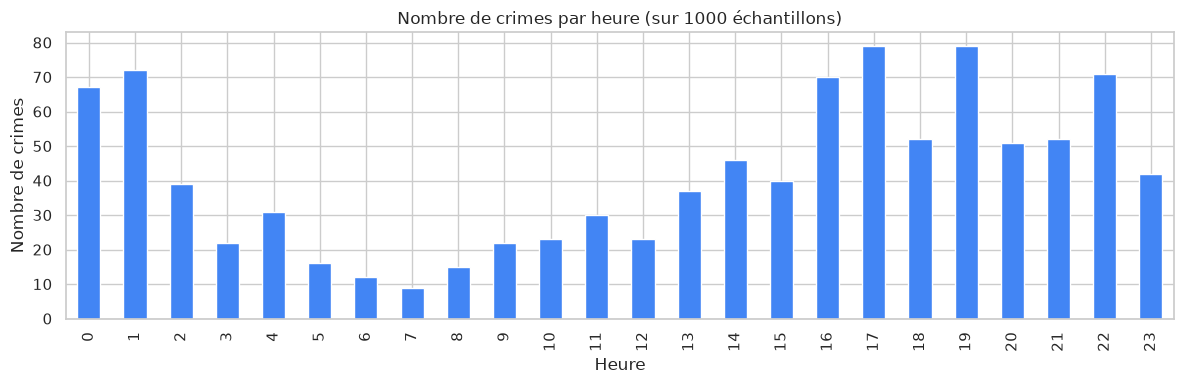

In [9]:
#Nombre de crime par heure
plt.figure(figsize=(12, 4))
df.groupby("hour").size().plot(kind="bar", color="#4285F4")
plt.title("Nombre de crimes par heure (sur 1000 échantillons)")
plt.xlabel("Heure")
plt.ylabel("Nombre de crimes")
plt.tight_layout()
plt.savefig("../docs/crimes_by_hour.png", dpi=150)
plt.show()

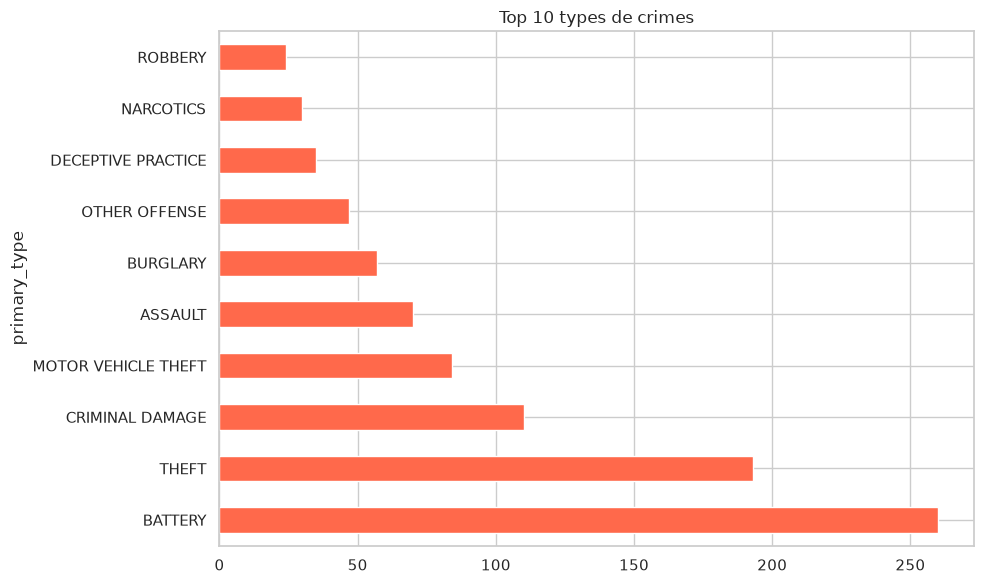

In [10]:
#Nombre de crime par type de crime

plt.figure(figsize=(10, 6))
df["primary_type"].value_counts().head(10).plot(kind="barh", color="#FF694B")
plt.title("Top 10 types de crimes")
plt.tight_layout()
plt.savefig("../docs/crimes_by_type.png", dpi=150)
plt.show()

In [11]:
#Taux d'arrestation

arrest_pct = df["arrest"].value_counts(normalize=True) * 100
print(f"Arrestations : {arrest_pct[True]:.1f}%")
print(f"Pas d'arrestation : {arrest_pct[False]:.1f}%")

Arrestations : 12.0%
Pas d'arrestation : 88.0%
